# 2 · Borrowing a prior from a bigger fleet

The conjugate update, the power prior and the bias-variance cost of borrowing. See [Lesson 2](../docs/lessons/02-borrowing-a-prior-from-a-bigger-fleet.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from smallfleet import plotting

plotting.use_style()
rng = np.random.default_rng(1)

In [2]:
from smallfleet.bayesian_point_estimation import (
    bayes_estimator,
    exact_performance,
    frequentist_estimator,
    jeffreys,
    power_prior,
)

for eq in (0.0, 10_000.0, 900_000.0):
    prior = jeffreys() if eq == 0 else power_prior(171, 900_000.0, eq)
    post = prior.update(1, 2100.0)
    print(f"equivalent {eq:>9,.0f} FH: mean {post.mean():.3f}, 90 % {post.interval()}")

equivalent         0 FH: mean 0.714, 90 % (0.08377293279744555, 1.8606495007740902)
equivalent    10,000 FH: mean 0.281, 90 % (0.08504366958976782, 0.5692201054591501)
equivalent   900,000 FH: mean 0.191, 90 % (0.16791917113830845, 0.21578182844830068)


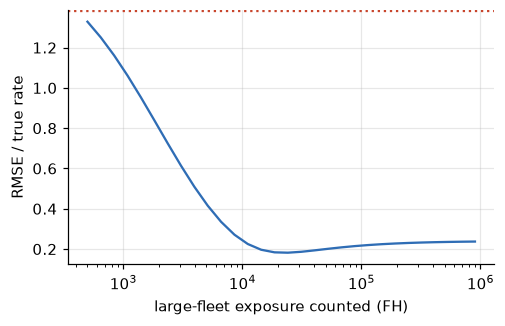

In [3]:
eqs = np.geomspace(500, 900_000, 30)
rmse = [exact_performance(bayes_estimator(power_prior(171, 900_000.0, e)), 0.25, 2100.0).rmse for e in eqs]
mle = exact_performance(frequentist_estimator(), 0.25, 2100.0).rmse
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogx(eqs, np.array(rmse) / 0.25, color=plotting.BAYES_COLOR)
ax.axhline(mle / 0.25, color=plotting.FREQUENTIST_COLOR, ls=":")
ax.set_xlabel("large-fleet exposure counted (FH)")
ax.set_ylabel("RMSE / true rate");